## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Tesher Baer

**Date:** [To be provided]

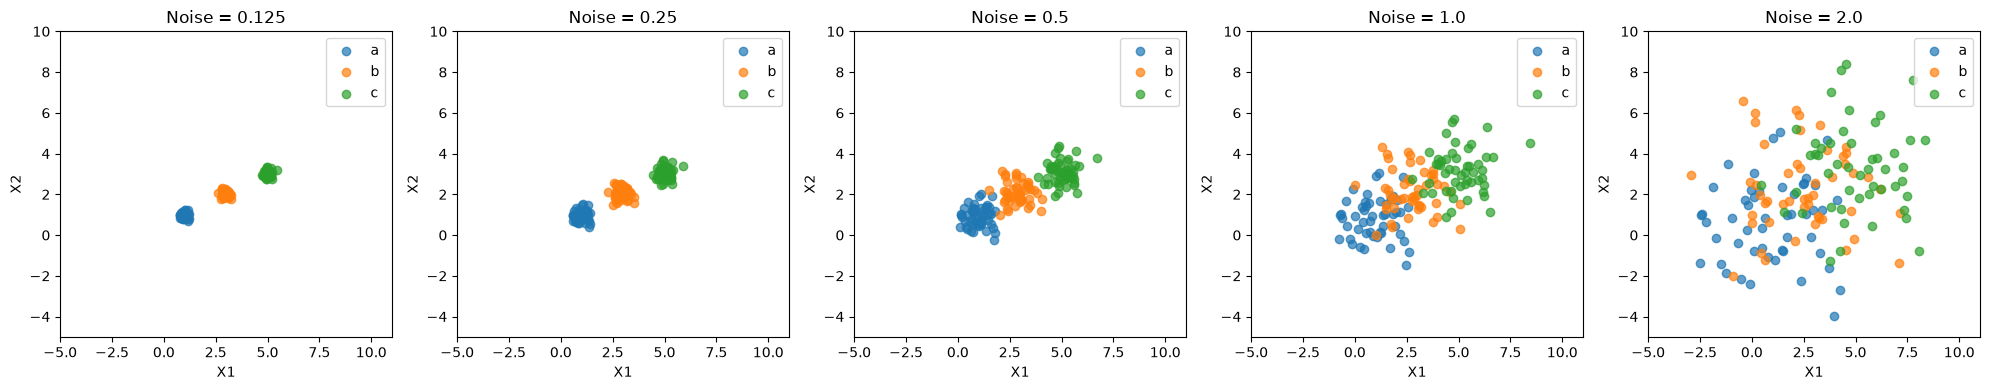

As the noise increases from 0.125 to 2.0, the clusters are less visually 
distinct. At low noise levels, the three groups form tight, clearly separated clusters. 
As noise increases, the points spread farther from their respective centers, causing the 
clusters to overlap. At the highest noise level, it is hard to distinguish the 
three groups visually, as their points are substantially intermixed. In short, as noise
levels increase, the visual division and distinction decreases.


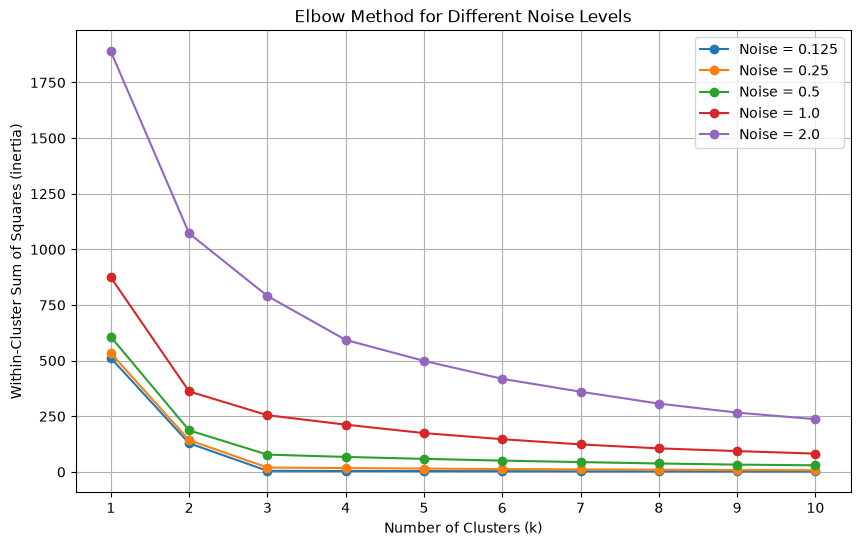

At lower noise levels, the scree plots show a relatively clear elbow around k = 2 and k =3, 
      corresponding to the three distinct groups in the original data. As noise increases, 
      the elbow becomes less pronounced because the clusters overlap more substantially. 
      This makes it increasingly difficult to identify an optimal number of clusters based 
      solely on the scree plot.
The elbow method attempts to identify the number of clusters that provides a good balance 
between minimizing within-cluster variation and avoiding unnecessary complexity.
When k is small, increasing the number of clusters can substantially reduce inertia because the 
algorithm can separate previously combined groups. However, once the major underlying clusters 
have been identified, adding more clusters produces diminishing improvements.
In this simulation, the original data contains three groups. At low noise levels, increasing k 
from 1 to 3 should dramatically reduce inertia because K-Means

In [8]:
# Your Phase 1 solution to the problem goes here.
#import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#question 1
def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


#question 2
#make the data sets
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
#control noise
noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]

#formatting 
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, df, noise in zip(axes, datasets, noise_levels):
    for group in ['a', 'b', 'c']:
        subset = df[df['group'] == group]
        ax.scatter(subset['x1'], subset['x2'], label=group, alpha=0.7)

    ax.set_title(f'Noise = {noise}')
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.set_xlim(-5, 11)
    ax.set_ylim(-5, 10)
    ax.legend()

plt.tight_layout()
plt.show()

print("""As the noise increases from 0.125 to 2.0, the clusters are less visually 
distinct. At low noise levels, the three groups form tight, clearly separated clusters. 
As noise increases, the points spread farther from their respective centers, causing the 
clusters to overlap. At the highest noise level, it is hard to distinguish the 
three groups visually, as their points are substantially intermixed. In short, as noise
levels increase, the visual division and distinction decreases.""")

#question 3

from sklearn.cluster import KMeans

k_values = range(1, 11)

plt.figure(figsize=(10, 6))

for df, noise in zip(datasets, noise_levels):
    X = df[['x1', 'x2']]

    inertias = []

    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)

    plt.plot(k_values, inertias, marker='o', label=f'Noise = {noise}')

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (inertia)')
plt.title('Elbow Method for Different Noise Levels')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

print("""At lower noise levels, the scree plots show a relatively clear elbow around k = 2 and k =3, 
      corresponding to the three distinct groups in the original data. As noise increases, 
      the elbow becomes less pronounced because the clusters overlap more substantially. 
      This makes it increasingly difficult to identify an optimal number of clusters based 
      solely on the scree plot.""")

#question 4
print("""The elbow method attempts to identify the number of clusters that provides a good balance 
between minimizing within-cluster variation and avoiding unnecessary complexity.
When k is small, increasing the number of clusters can substantially reduce inertia because the 
algorithm can separate previously combined groups. However, once the major underlying clusters 
have been identified, adding more clusters produces diminishing improvements.
In this simulation, the original data contains three groups. At low noise levels, increasing k 
from 1 to 3 should dramatically reduce inertia because K-Means can identify these three distinct 
clusters. Beyond k = 3, additional clusters provide relatively small improvements, creating an 
elbow in the scree plot.
At higher noise levels, the groups overlap, making it harder for K-Means to identify their 
underlying structure. Consequently, the reduction in inertia becomes more gradual, and the elbow 
is less obvious.""")


Number of countries: 148
index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
1,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
2,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
3,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
4,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


The index and Year columns should also be excluded from the 
clustering analysis because they are not meaningful spending characteristics.


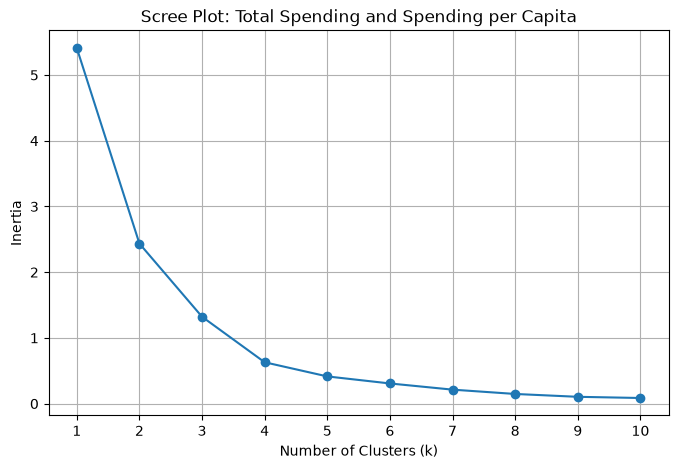

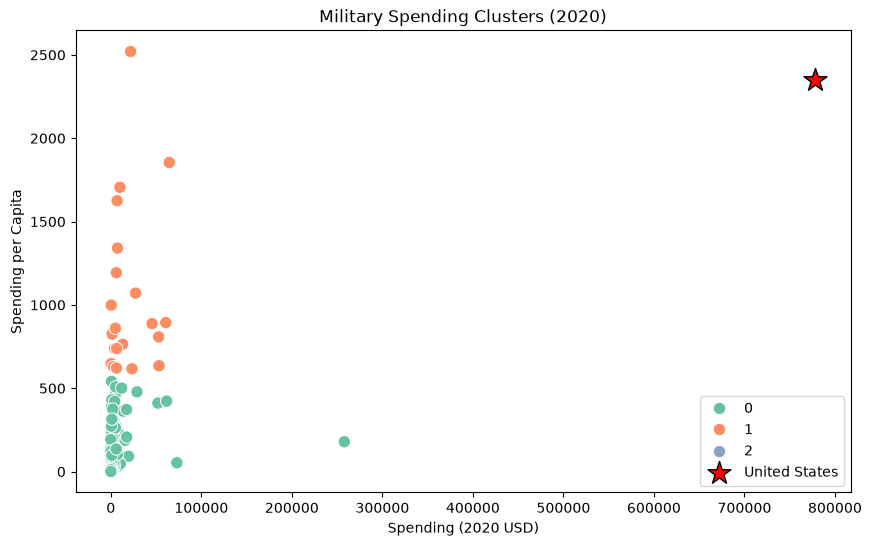

Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster2                                                                   
0                      126.0    5943.346303  24858.961064       8.622460   
1                       21.0   19975.991473  21749.736747     405.790494   
2                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster2                                                               
0            162.761743     580.758315    3225.333414  257973.429834   
1           4980.428135    7269.880030   27300.894701   64558.400000   
2         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita                                        \
                       count         mean         std          min   
cluster2                                                             
0                      126.0   122.034996  140.041183     0.580129   
1                       21.0  1046.433509  501.631845   616.854430   
2                        1.0  2351.631858         NaN  2351.631858   

                                                              
                  25%          50%          75%          max  
cluster2                                                      
0           18.505805    58.809109   188.249364   541.154778  
1          737.690186   859.880548  1193.598730  2520.398541  
2         2351.631858  2351.631858  2351.631858  2351.631858

cluster2
0    126
1     21
2      1
Name: count, dtype: int64
                      Country  cluster2
144  United States of America         2

Cluster 0:
['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Austria', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic', 'Croatia', 'Cyprus', 'Czechia', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Estonia', 'Ethiopia', 'Fiji', 'Gabon', 'Gambia, The', 'Georgia', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'India', 'Indonesia', 'Iran', 'Iraq', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kyrgyz Republic', 'Latvia', 'Lebanon', 'Lesotho', 'Liberia', 

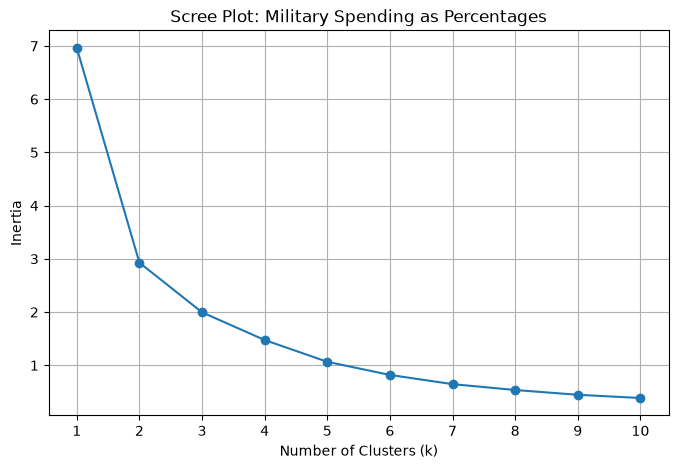

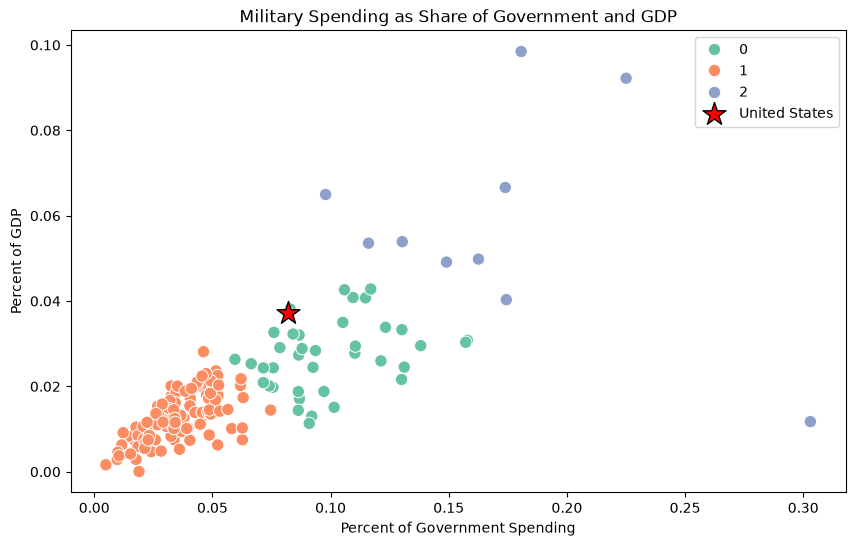

Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  99.0  0.035777  0.014549  0.004896   
2                                  10.0  0.171289  0.058725  0.097882   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                      
               std       min       25%       50%       75%       max  
cluster3                                                              
0         0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1         0.005681  0.000054  0.008393  0.013191  0.016752  0.028132  
2         0.024867  0.011742  0.049297  0.053729  0.066190  0.098470

cluster3
0    39
1    99
2    10
Name: count, dtype: int64
                      Country  cluster3
144  United States of America         0

Cluster 0:
['Bahrain', 'Bangladesh', 'Botswana', 'Brunei', 'Burkina Faso', 'Burundi', 'Cambodia', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Congo, Republic', 'Ecuador', 'Equatorial Guinea', 'Gabon', 'Guinea', 'India', 'Iran', 'Iraq', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Niger', 'Russia', 'Singapore', 'South Sudan', 'Sri Lanka', 'Sudan', 'Taiwan', 'Togo', 'Tunisia', 'Turkey', 'Uganda', 'Ukraine', 'United States of America']

Cluster 1:
['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Cameroon', 'Canada', 'Cape Verde', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France

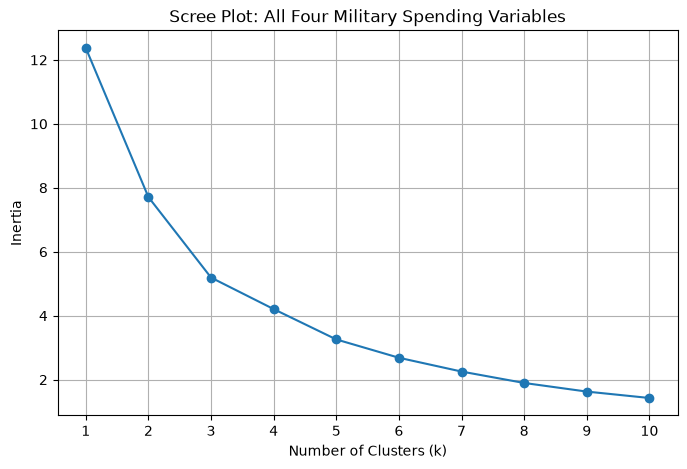

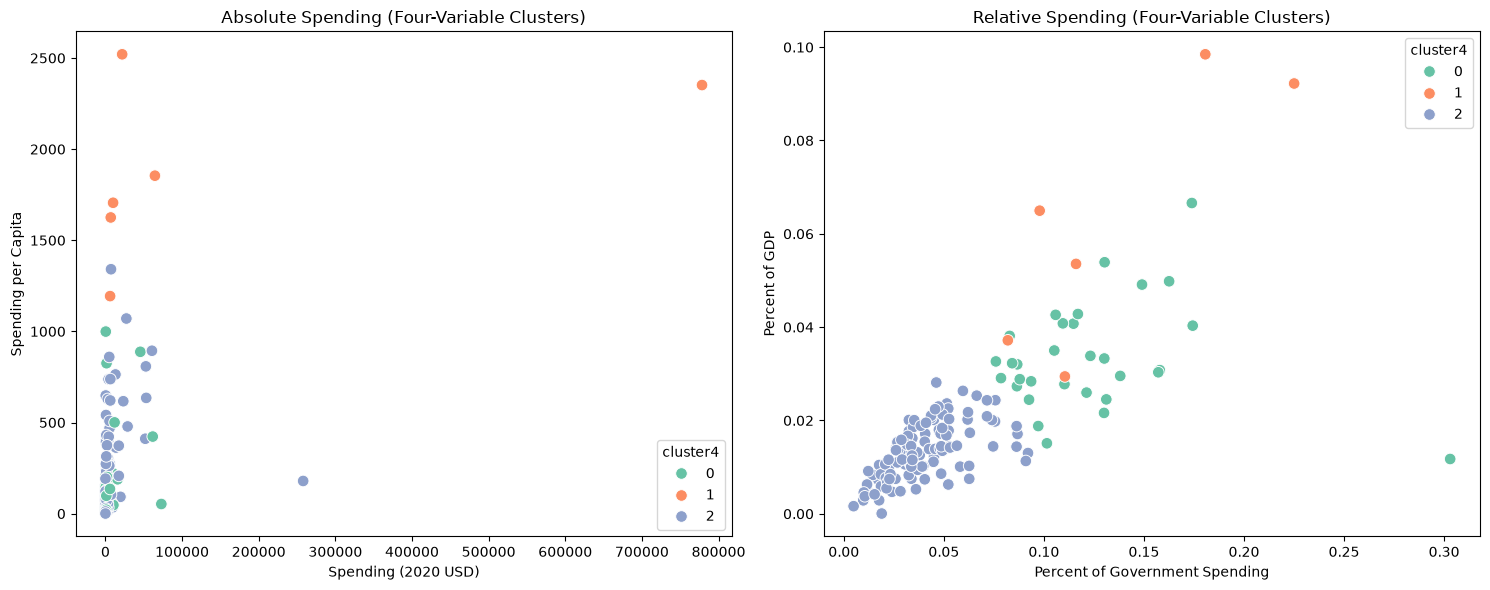

Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                       31.0    8786.086602   17901.909108   162.373364   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                      111.0    7086.472777   26479.379918     8.622460   

                                                                  \
                  25%           50%           75%            max   
cluster4                                                           
0          467.787851   1404.787234   7739.166193   72937.064048   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2          130.010211    567.650747   3910.107493  257973.429834   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...                            75%   
cluster4                                   ...                                  
0                       31.0   212.689100  ...                       0.134663   
1                        6.0  1875.150751  ...                       0.164503   
2                      111.0   196.926833  ...                       0.050505   

                   Percent of GDP                                          \
               max          count      mean       std       min       25%   
cluster4                                                                    
0         0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
1         0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2         0.092044          111.0  0.013419  0.005996  0.000054  0.008873   

                                        
               50%       75%       max  
cluster4                                
0         0.032024  0.040531  0.066600  
1         0.059257  0.085398  0.098470  
2         0.013589  0.017769  0.028132  

[3 rows x 32 columns]

cluster4
0     31
1      6
2    111
Name: count, dtype: int64
                      Country  cluster2  cluster3  cluster4
144  United States of America         2         0         1

Cluster 0:
['Algeria', 'Armenia', 'Azerbaijan', 'Bahrain', 'Belarus', 'Botswana', 'Brunei', 'Burkina Faso', 'Cambodia', 'Chad', 'Colombia', 'Congo, Republic', 'Equatorial Guinea', 'India', 'Iran', 'Iraq', 'Jordan', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Pakistan', 'Russia', 'Taiwan', 'Togo', 'Tunisia', 'Uganda', 'Ukraine']

Cluster 1:
['Israel', 'Kuwait', 'Oman', 'Saudi Arabia', 'Singapore', 'United States of America']

Cluster 2:
['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Bangladesh', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Burundi', 'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic', 'Chile', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican R

In [8]:
#part 2
#packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

# Load the dataset
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')

# Select 2020 and drop missing values
df2020 = df[df['Year'] == 2020].dropna().copy()

# Reset  index
df2020 = df2020.reset_index(drop=True)

# Check countries 
print("Number of countries:", len(df2020))

# examine data 
print(df2020.dtypes)
display(df2020.head())

print("""The index and Year columns should also be excluded from the 
clustering analysis because they are not meaningful spending characteristics.""")

#question 2 

# Select  variables
cols2 = ['Spending (2020 USD)', 'Spending per Capita']

# Min-max normalization
scaler = MinMaxScaler()
X2 = scaler.fit_transform(df2020[cols2])

# Calculate inertia for k = 1 through 10
inertias2 = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X2)
    inertias2.append(kmeans.inertia_)

# Scree plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertias2, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot: Total Spending and Spending per Capita')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


# k stuff
k2 = 3

# Fit K-Means
kmeans2 = KMeans(n_clusters=k2, random_state=42, n_init=10)
df2020['cluster2'] = kmeans2.fit_predict(X2)

# Scatterplot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df2020,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    hue='cluster2',
    palette='Set2',
    s=80
)

# US
usa = df2020[df2020['Country'] == 'United States of America']

plt.scatter(
    usa['Spending (2020 USD)'],
    usa['Spending per Capita'],
    color='red',
    marker='*',
    s=300,
    edgecolor='black',
    label='United States'
)

plt.title('Military Spending Clusters (2020)')
plt.legend()
plt.show()


# Descriptive statistics by cluster
display(df2020.groupby('cluster2')[cols2].describe())

# Number of countries in each cluster
print(df2020['cluster2'].value_counts().sort_index())

# Identify the US cluster
print(df2020.loc[
    df2020['Country'] == 'United States of America',
    ['Country', 'cluster2']
])

# See which countries belong to each cluster
for cluster in sorted(df2020['cluster2'].unique()):
    print(f'\nCluster {cluster}:')
    print(df2020.loc[
        df2020['cluster2'] == cluster, 'Country'
    ].tolist())
print("""Most countries are grouped together at comparatively low spending levels, 
while a smaller group exhibits substantially higher spending per person. This is probably 
because the US just spends a lot on military things.""")

#question 3

cols3 = ['Percent of Government Spending', 'Percent of GDP']

scaler3 = MinMaxScaler()
X3 = scaler3.fit_transform(df2020[cols3])

inertias3 = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X3)
    inertias3.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertias3, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot: Military Spending as Percentages')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


k3 = 3

kmeans3 = KMeans(n_clusters=k3, random_state=42, n_init=10)
df2020['cluster3'] = kmeans3.fit_predict(X3)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df2020,
    x='Percent of Government Spending',
    y='Percent of GDP',
    hue='cluster3',
    palette='Set2',
    s=80
)

usa = df2020[df2020['Country'] == 'United States of America']

plt.scatter(
    usa['Percent of Government Spending'],
    usa['Percent of GDP'],
    color='red',
    marker='*',
    s=300,
    edgecolor='black',
    label='United States'
)

plt.title('Military Spending as Share of Government and GDP')
plt.legend()
plt.show()

display(df2020.groupby('cluster3')[cols3].describe())

print(df2020['cluster3'].value_counts().sort_index())

print(df2020.loc[
    df2020['Country'] == 'United States of America',
    ['Country', 'cluster3']
])

for cluster in sorted(df2020['cluster3'].unique()):
    print(f'\nCluster {cluster}:')
    print(df2020.loc[
        df2020['cluster3'] == cluster, 'Country'
    ].tolist())

print("""Compared to Question 2, the clusters are more evenly distributed, and the United States 
is no longer an isolated outlier. This suggests that absolute military spending and the 
proportion of national resources devoted to military spending capture different aspects of 
countries' defense priorities.""")

#question 4

cols4 = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

scaler4 = MinMaxScaler()
X4 = scaler4.fit_transform(df2020[cols4])

inertias4 = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X4)
    inertias4.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertias4, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot: All Four Military Spending Variables')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


k4 = 3

kmeans4 = KMeans(n_clusters=k4, random_state=42, n_init=10)
df2020['cluster4'] = kmeans4.fit_predict(X4)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=df2020,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    hue='cluster4',
    palette='Set2',
    s=70,
    ax=axes[0]
)

axes[0].set_title('Absolute Spending (Four-Variable Clusters)')

sns.scatterplot(
    data=df2020,
    x='Percent of Government Spending',
    y='Percent of GDP',
    hue='cluster4',
    palette='Set2',
    s=70,
    ax=axes[1]
)

axes[1].set_title('Relative Spending (Four-Variable Clusters)')

plt.tight_layout()
plt.show()


display(df2020.groupby('cluster4')[cols4].describe())

print(df2020['cluster4'].value_counts().sort_index())

print(df2020.loc[
    df2020['Country'] == 'United States of America',
    ['Country', 'cluster2', 'cluster3', 'cluster4']
])

for cluster in sorted(df2020['cluster4'].unique()):
    print(f'\nCluster {cluster}:')
    print(df2020.loc[
        df2020['cluster4'] == cluster, 'Country'
    ].tolist())
print("""Combining all four variables produces clusters that reflect both the scale of 
military spending and its relative importance within national economies. Unlike Question 2, 
the United States is no longer isolated in its own cluster, suggesting that other countries 
share some of its spending characteristics when multiple dimensions are considered. The combined
analysis provides a more comprehensive picture of military spending than either pair of 
variables alone.""")

#question 5
print("""K-Means clustering revealed useful patterns in military spending, particularly the 
distinction between absolute expenditure and spending relative to national economic resources. 
When clustering countries by total spending and spending per capita, the United States emerged 
as an extreme outlier. However, when considering military spending as a percentage of GDP and 
government expenditure, the United States was grouped with several other countries. This 
demonstrates that high absolute military expenditure does not necessarily correspond to an 
equally exceptional share of national resources devoted to defense.
Combining all four variables produced a more nuanced classification of countries, separating 
those with relatively low spending, those allocating a larger proportion of national resources 
to defense, and those with particularly high per-capita expenditures.
However, the results also illustrate limitations of K-Means. Cluster membership depends on the 
variables selected, the normalization method, and the chosen number of clusters. Furthermore, 
the algorithm identifies similarities in numerical spending patterns but cannot independently 
explain the political, economic, or security factors underlying them. Overall, 
K-Means was useful for identifying broad spending patterns, but additional contextual analysis 
would be necessary to explain why countries fall into particular clusters.""")

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]